# Cross-Modal Self-Supervised Representation Learning for Joint Analysis of Wearable Physiological and Motion Signals

In [1]:
# Importing relevant libraries.
import os
import re
import copy
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

PyTorch: 2.11.0+cpu
Device: cpu


# Project Configuration

In [2]:
DATA_DIR = Path(r"C:\Users\user\Desktop\MHEALTHDATASET")
FS = 50
WINDOW_SIZE = 250       
STRIDE = 125           
BATCH_SIZE = 64
PRETRAIN_EPOCHS = 40
RECON_EPOCHS = 30
ABLATION_EPOCHS = 30
LEARNING_RATE = 5e-4
TEMPERATURE = 0.1
NUM_WORKERS = 0
OUTPUT_DIR = Path("mhealth_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
print("Dataset folder exists:", DATA_DIR.exists())
print("Output folder:", OUTPUT_DIR.resolve())

Dataset folder exists: True
Output folder: C:\Users\user\mhealth_outputs


# Loading all ten participants csv files

In [3]:
if not DATA_DIR.exists():
    raise FileNotFoundError(f"Dataset folder not found: {DATA_DIR}")
all_files = [
    p for p in DATA_DIR.iterdir()
    if p.is_file() and re.search(r"mhealth_subject\d+", p.name.lower())
]
def subject_number(path):
    match = re.search(r"subject(\d+)", path.name.lower())
    return int(match.group(1)) if match else 999
all_files = sorted(all_files, key=subject_number)
if len(all_files) != 10:
    print(f"Warning: found {len(all_files)} matching files, expected 10.")
    print([p.name for p in all_files])
def read_subject_file(path):
    suffix = path.suffix.lower()

    if suffix in [".log", ".txt"]:
        frame = pd.read_csv(path, sep=r"\s+", header=None, engine="python")
    elif suffix == ".csv":
        frame = pd.read_csv(path, header=None)
    elif suffix in [".xlsx", ".xls"]:
        frame = pd.read_excel(path, header=None)
    else:
        raise ValueError(f"Unsupported file type: {path.name}")

    frame = frame.apply(pd.to_numeric, errors="coerce")
    frame = frame.dropna(axis=0, how="any")

    if frame.shape[1] != 24:
        raise ValueError(
            f"{path.name} has {frame.shape[1]} columns; expected 24."
        )

    return frame.to_numpy(dtype=np.float32)
subject_data = {}
for path in all_files:
    sid = subject_number(path)
    subject_data[sid] = read_subject_file(path)
    print(f"Subject {sid}: {subject_data[sid].shape}")
if len(subject_data) == 0:
    raise RuntimeError("No participant files were loaded.")

Subject 1: (161280, 24)
Subject 2: (130561, 24)
Subject 3: (122112, 24)
Subject 4: (116736, 24)
Subject 5: (119808, 24)
Subject 6: (98304, 24)
Subject 7: (104448, 24)
Subject 8: (129024, 24)
Subject 9: (135168, 24)
Subject 10: (98304, 24)


# Confirm the sensor-column mapping

In [4]:
# Original 24-column of MHEALTH layout:
# 0:3   chest accelerometer
# 3:5   ECG leads
# 5:8   left ankle accelerometer
# 8:11  left ankle gyroscope
# 11:14 left ankle magnetometer
# 14:17 right arm accelerometer
# 17:20 right arm gyroscope
# 20:23 right arm magnetometer
# 23    activity label
print("Expected columns: 24")
print("Chest accelerometer: 3")
print("ECG: 2")
print("Left ankle IMU: 9")
print("Right arm IMU: 9")
print("Activity label: 1")

Expected columns: 24
Chest accelerometer: 3
ECG: 2
Left ankle IMU: 9
Right arm IMU: 9
Activity label: 1


# Inspect activity labels for each participant

In [5]:
activity_names = {
    0: "Null", 1: "Standing", 2: "Sitting", 3: "Lying",
    4: "Walking", 5: "Climbing stairs", 6: "Waist bends",
    7: "Frontal arm elevation", 8: "Knees bending",
    9: "Cycling", 10: "Jogging", 11: "Running",
    12: "Jumping"
}
for sid, data in subject_data.items():
    labels, counts = np.unique(data[:, 23].astype(int), return_counts=True)
    print(f"\nSubject {sid}")
    for label, count in zip(labels, counts):
        print(f"Activity {label:2d} ({activity_names.get(label, 'Unknown')}): {count}")


Subject 1
Activity  0 (Null): 126106
Activity  1 (Standing): 3072
Activity  2 (Sitting): 3072
Activity  3 (Lying): 3072
Activity  4 (Walking): 3072
Activity  5 (Climbing stairs): 3072
Activity  6 (Waist bends): 3072
Activity  7 (Frontal arm elevation): 3072
Activity  8 (Knees bending): 3379
Activity  9 (Cycling): 3072
Activity 10 (Jogging): 3072
Activity 11 (Running): 3072
Activity 12 (Jumping): 1075

Subject 2
Activity  0 (Null): 95029
Activity  1 (Standing): 3072
Activity  2 (Sitting): 3072
Activity  3 (Lying): 3072
Activity  4 (Walking): 3072
Activity  5 (Climbing stairs): 3072
Activity  6 (Waist bends): 3174
Activity  7 (Frontal arm elevation): 3328
Activity  8 (Knees bending): 3430
Activity  9 (Cycling): 3072
Activity 10 (Jogging): 3072
Activity 11 (Running): 3072
Activity 12 (Jumping): 1024

Subject 3
Activity  0 (Null): 86732
Activity  1 (Standing): 3072
Activity  2 (Sitting): 3072
Activity  3 (Lying): 3072
Activity  4 (Walking): 3072
Activity  5 (Climbing stairs): 3072
Activit

# Extract synchronized 5-second windows

In [6]:
ecg_windows, imu_windows = [], []
window_labels, window_purities, window_subjects = [], [], []
for sid, data in subject_data.items():
    ecg = data[:, 3:5]
    imu = np.concatenate([data[:, 0:3], data[:, 5:23]], axis=1)
    labels = data[:, 23].astype(int)

    for start in range(0, len(data) - WINDOW_SIZE + 1, STRIDE):
        end = start + WINDOW_SIZE

        ecg_segment = ecg[start:end]
        imu_segment = imu[start:end]
        label_segment = labels[start:end]

        values, counts = np.unique(label_segment, return_counts=True)
        winner = int(values[np.argmax(counts)])
        purity = float(np.max(counts) / WINDOW_SIZE)

        ecg_windows.append(ecg_segment)
        imu_windows.append(imu_segment)
        window_labels.append(winner)
        window_purities.append(purity)
        window_subjects.append(sid)
X_ecg = np.asarray(ecg_windows, dtype=np.float32)
X_imu = np.asarray(imu_windows, dtype=np.float32)
y = np.asarray(window_labels, dtype=np.int64)
purity = np.asarray(window_purities, dtype=np.float32)
subjects = np.asarray(window_subjects, dtype=np.int64)
print("ECG:", X_ecg.shape)
print("IMU:", X_imu.shape)
print("Labels:", y.shape)
print("Purity:", purity.shape)

ECG: (9711, 250, 2)
IMU: (9711, 250, 21)
Labels: (9711,)
Purity: (9711,)


# Inspect extracted activity distribution

,Activity,Name,Windows
0,0,Null,6965
1,1,Standing,247
2,2,Sitting,246
3,3,Lying,245
4,4,Walking,244
5,5,Climbing stairs,247
6,6,Waist bends,227
7,7,Frontal arm elevation,236
8,8,Knees bending,236
9,9,Cycling,246


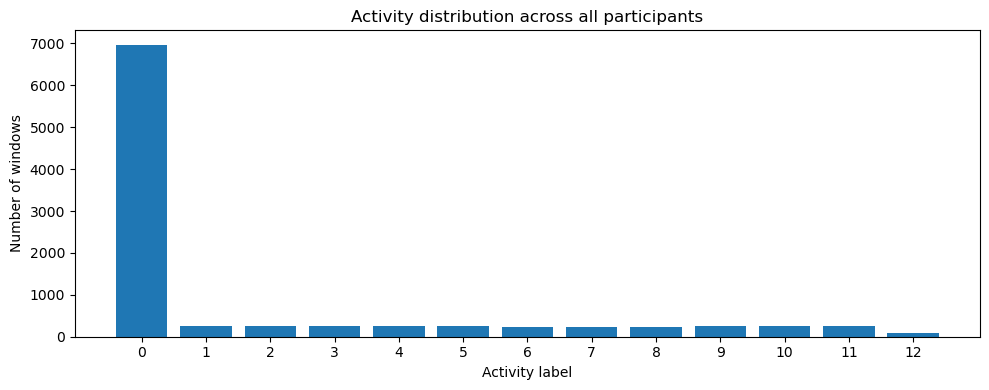

In [7]:
unique_labels, counts = np.unique(y, return_counts=True)
activity_counts = pd.DataFrame({
    "Activity": unique_labels,
    "Name": [activity_names.get(v, "Unknown") for v in unique_labels],
    "Windows": counts
})
display(activity_counts)
plt.figure(figsize=(10, 4))
plt.bar(activity_counts["Activity"].astype(str), activity_counts["Windows"])
plt.xlabel("Activity label")
plt.ylabel("Number of windows")
plt.title("Activity distribution across all participants")
plt.tight_layout()
plt.show()

# Split by participant

In [8]:
train_mask = np.isin(subjects, np.arange(1, 9))
val_mask = subjects == 9
test_mask = subjects == 10
X_ecg_train_raw, X_ecg_val_raw, X_ecg_test_raw = (
    X_ecg[train_mask].copy(), X_ecg[val_mask].copy(), X_ecg[test_mask].copy()
)
X_imu_train_raw, X_imu_val_raw, X_imu_test_raw = (
    X_imu[train_mask].copy(), X_imu[val_mask].copy(), X_imu[test_mask].copy()
)
y_train, y_val, y_test = y[train_mask], y[val_mask], y[test_mask]
purity_train, purity_val, purity_test = (
    purity[train_mask], purity[val_mask], purity[test_mask]
)
print("Train windows:", len(y_train), "Subjects 1-8")
print("Validation windows:", len(y_val), "Subject 9")
print("Test windows:", len(y_test), "Subject 10")
if min(len(y_train), len(y_val), len(y_test)) == 0:
    raise RuntimeError("A data split is empty. Check participant file loading.")

Train windows: 7846 Subjects 1-8
Validation windows: 1080 Subject 9
Test windows: 785 Subject 10


# Normalize ECG and IMU channel-wise using training data only

In [9]:
# Arrays at this stage have shape (windows, time, channels).
# Calculate one mean and standard deviation per channel over windows and time.
ecg_mean = X_ecg_train_raw.mean(axis=(0, 1), keepdims=True)
ecg_std = X_ecg_train_raw.std(axis=(0, 1), keepdims=True)
ecg_std = np.maximum(ecg_std, 1e-8)
imu_mean = X_imu_train_raw.mean(axis=(0, 1), keepdims=True)
imu_std = X_imu_train_raw.std(axis=(0, 1), keepdims=True)
imu_std = np.maximum(imu_std, 1e-8)
X_ecg_train = ((X_ecg_train_raw - ecg_mean) / ecg_std).astype(np.float32)
X_ecg_val = ((X_ecg_val_raw - ecg_mean) / ecg_std).astype(np.float32)
X_ecg_test = ((X_ecg_test_raw - ecg_mean) / ecg_std).astype(np.float32)
X_imu_train = ((X_imu_train_raw - imu_mean) / imu_std).astype(np.float32)
X_imu_val = ((X_imu_val_raw - imu_mean) / imu_std).astype(np.float32)
X_imu_test = ((X_imu_test_raw - imu_mean) / imu_std).astype(np.float32)
print("ECG normalized shapes:", X_ecg_train.shape, X_ecg_val.shape, X_ecg_test.shape)
print("IMU normalized shapes:", X_imu_train.shape, X_imu_val.shape, X_imu_test.shape)

ECG normalized shapes: (7846, 250, 2) (1080, 250, 2) (785, 250, 2)
IMU normalized shapes: (7846, 250, 21) (1080, 250, 21) (785, 250, 21)


# Verify the normalization

In [10]:
print("Training ECG channel means:", np.round(X_ecg_train.mean(axis=(0, 1)), 4))
print("Training ECG channel stds: ", np.round(X_ecg_train.std(axis=(0, 1)), 4))
print("\nTraining IMU channel means:", np.round(X_imu_train.mean(axis=(0, 1)), 4))
print("Training IMU channel stds: ", np.round(X_imu_train.std(axis=(0, 1)), 4))
assert X_ecg_train.shape[1:] == (WINDOW_SIZE, 2)
assert X_imu_train.shape[1:] == (WINDOW_SIZE, 21)
assert np.allclose(X_ecg_train.mean(axis=(0, 1)), 0, atol=1e-4)
assert np.allclose(X_imu_train.std(axis=(0, 1)), 1, atol=1e-3)
print("\nNormalization verification passed.")

Training ECG channel means: [-0. -0.]
Training ECG channel stds:  [0.9998 0.9999]

Training IMU channel means: [ 0.003   0.      0.     -0.      0.0126  0.      0.     -0.001   0.0002
  0.      0.     -0.     -0.0002 -0.0008  0.0002 -0.0003  0.0001  0.
 -0.     -0.     -0.    ]
Training IMU channel stds:  [1.     1.     1.0002 1.0002 0.9999 1.     0.9999 0.9998 0.9998 1.
 1.0001 1.0001 1.     0.9999 1.     1.     1.0004 0.9999 1.0001 1.
 0.9999]

Normalization verification passed.


# Creating PyTorch Dataset and DataLoaders

In [11]:
class PairedSignalDataset(Dataset):
    def __init__(self, ecg, imu):
        # Input arrays: (N, T, C); model input: (N, C, T)
        self.ecg = torch.from_numpy(ecg).permute(0, 2, 1).contiguous()
        self.imu = torch.from_numpy(imu).permute(0, 2, 1).contiguous()

    def __len__(self):
        return len(self.ecg)

    def __getitem__(self, index):
        return self.ecg[index], self.imu[index]
train_dataset = PairedSignalDataset(X_ecg_train, X_imu_train)
val_dataset = PairedSignalDataset(X_ecg_val, X_imu_val)
test_dataset = PairedSignalDataset(X_ecg_test, X_imu_test)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, drop_last=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS
)
print("ECG batch:", next(iter(train_loader))[0].shape)
print("IMU batch:", next(iter(train_loader))[1].shape)

ECG batch: torch.Size([64, 2, 250])
IMU batch: torch.Size([64, 21, 250])


# Defining signal augmentation

In [12]:
def augment_signal(x):
    # x shape: (batch, channels, time)
    x_aug = x.clone()

    noise = torch.randn_like(x_aug) * 0.03
    scale = torch.empty(
        x_aug.size(0), 1, 1, device=x_aug.device
    ).uniform_(0.9, 1.1)

    x_aug = x_aug * scale + noise

    # Randomly mask a short time segment for each sample
    if x_aug.size(-1) > 20:
        for i in range(x_aug.size(0)):
            if random.random() < 0.5:
                width = random.randint(5, 20)
                start = random.randint(0, x_aug.size(-1) - width)
                x_aug[i, :, start:start + width] = 0

    return x_aug

# Define the 1D CNN encoder

In [13]:
class SignalEncoder(nn.Module):
    def __init__(self, in_channels, representation_dim=128, projection_dim=64):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(in_channels, 32, kernel_size=7, stride=2, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(32, 64, kernel_size=5, stride=1, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        self.representation = nn.Linear(128, representation_dim)
        self.projector = nn.Sequential(
            nn.Linear(representation_dim, 128),
            nn.ReLU(),
            nn.Linear(128, projection_dim)
        )

    def forward(self, x):
        h = self.features(x).squeeze(-1)
        h = self.representation(h)
        z = F.normalize(self.projector(h), dim=1)
        return h, z

# Define the paired cross-modal model

In [14]:
class CrossModalModel(nn.Module):
    def __init__(self, imu_channels=21):
        super().__init__()
        self.ecg_encoder = SignalEncoder(2)
        self.imu_encoder = SignalEncoder(imu_channels)

    def forward(self, ecg, imu):
        h_ecg, z_ecg = self.ecg_encoder(ecg)
        h_imu, z_imu = self.imu_encoder(imu)
        return h_ecg, z_ecg, h_imu, z_imu
model = CrossModalModel().to(DEVICE)
print("Model initialized.")

Model initialized.


# Define symmetric cross-modal InfoNCE loss

In [15]:
def contrastive_loss(z_ecg, z_imu, temperature=TEMPERATURE):
    logits = torch.matmul(z_ecg, z_imu.T) / temperature
    targets = torch.arange(logits.size(0), device=logits.device)

    loss_ecg_to_imu = F.cross_entropy(logits, targets)
    loss_imu_to_ecg = F.cross_entropy(logits.T, targets)

    return 0.5 * (loss_ecg_to_imu + loss_imu_to_ecg)

# Define one training / validation epoch

In [16]:
def run_contrastive_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    losses = []

    for ecg, imu in loader:
        ecg, imu = ecg.to(DEVICE), imu.to(DEVICE)
        ecg_aug = augment_signal(ecg)
        imu_aug = augment_signal(imu)

        with torch.set_grad_enabled(training):
            _, z_ecg, _, z_imu = model(ecg_aug, imu_aug)
            loss = contrastive_loss(z_ecg, z_imu)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        losses.append(loss.item())

    return float(np.mean(losses))

# Train the cross-modal contrastive model

In [17]:
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-5)
history = {"train_loss": [], "val_loss": []}
best_val_loss = float("inf")
best_model_state = copy.deepcopy(model.state_dict())
for epoch in range(PRETRAIN_EPOCHS):
    train_loss = run_contrastive_epoch(model, train_loader, optimizer)
    val_loss = run_contrastive_epoch(model, val_loader)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        torch.save(best_model_state, OUTPUT_DIR / "best_cross_modal_mhealth.pth")

    print(
        f"Epoch {epoch + 1:02d}/{PRETRAIN_EPOCHS} | "
        f"Train: {train_loss:.4f} | Val: {val_loss:.4f}"
    )
model.load_state_dict(best_model_state)

Epoch 01/40 | Train: 3.2897 | Val: 4.1783
Epoch 02/40 | Train: 2.4191 | Val: 4.2935
Epoch 03/40 | Train: 1.9007 | Val: 4.5934
Epoch 04/40 | Train: 1.6357 | Val: 4.7285
Epoch 05/40 | Train: 1.5008 | Val: 4.8106
Epoch 06/40 | Train: 1.3651 | Val: 4.6407
Epoch 07/40 | Train: 1.2777 | Val: 4.8193
Epoch 08/40 | Train: 1.2069 | Val: 4.7928
Epoch 09/40 | Train: 1.1420 | Val: 4.7558
Epoch 10/40 | Train: 1.0917 | Val: 4.9034
Epoch 11/40 | Train: 1.0315 | Val: 4.8089
Epoch 12/40 | Train: 0.9986 | Val: 4.6813
Epoch 13/40 | Train: 0.9651 | Val: 4.8261
Epoch 14/40 | Train: 0.9222 | Val: 4.6527
Epoch 15/40 | Train: 0.9037 | Val: 4.9346
Epoch 16/40 | Train: 0.8670 | Val: 4.7424
Epoch 17/40 | Train: 0.8301 | Val: 4.8154
Epoch 18/40 | Train: 0.8173 | Val: 4.8777
Epoch 19/40 | Train: 0.7741 | Val: 4.7516
Epoch 20/40 | Train: 0.7674 | Val: 4.8637
Epoch 21/40 | Train: 0.7486 | Val: 4.7555
Epoch 22/40 | Train: 0.7186 | Val: 4.8821
Epoch 23/40 | Train: 0.7051 | Val: 4.8602
Epoch 24/40 | Train: 0.7004 | Val:

<All keys matched successfully>

# Extract frozen representations

In [18]:
@torch.no_grad()
def extract_embeddings(model, loader):
    model.eval()
    ecg_reps, imu_reps = [], []

    for ecg, imu in loader:
        ecg, imu = ecg.to(DEVICE), imu.to(DEVICE)
        h_ecg, _, h_imu, _ = model(ecg, imu)
        ecg_reps.append(h_ecg.cpu().numpy())
        imu_reps.append(h_imu.cpu().numpy())

    return np.concatenate(ecg_reps), np.concatenate(imu_reps)
Z_ecg_train, Z_imu_train = extract_embeddings(model, DataLoader(train_dataset, batch_size=BATCH_SIZE))
Z_ecg_val, Z_imu_val = extract_embeddings(model, val_loader)
Z_ecg_test, Z_imu_test = extract_embeddings(model, test_loader)
Z_fused_train = np.concatenate([Z_ecg_train, Z_imu_train], axis=1)
Z_fused_test = np.concatenate([Z_ecg_test, Z_imu_test], axis=1)
print("Fused train:", Z_fused_train.shape)
print("Fused test:", Z_fused_test.shape)

Fused train: (7846, 256)
Fused test: (785, 256)


# Preparing clean activity-classification subsets

In [19]:
# Exclude null activity and windows with less than 80% label purity.
train_eval_mask = (y_train != 0) & (purity_train >= 0.80)
test_eval_mask = (y_test != 0) & (purity_test >= 0.80)
y_train_eval = y_train[train_eval_mask]
y_test_eval = y_test[test_eval_mask]
print("Training evaluation windows:", len(y_train_eval))
print("Test evaluation windows:", len(y_test_eval))
print("Training classes:", np.unique(y_train_eval))
print("Test classes:", np.unique(y_test_eval))
if len(y_test_eval) == 0:
    raise RuntimeError("No eligible test windows after filtering.")

Training evaluation windows: 2076
Test evaluation windows: 256
Training classes: [ 1  2  3  4  5  6  7  8  9 10 11 12]
Test classes: [ 1  2  3  4  5  6  7  8  9 10 11 12]


# Train and evaluate linear probes

In [20]:
def evaluate_linear_probe(Z_train, Z_test, name):
    Xtr = Z_train[train_eval_mask]
    Xte = Z_test[test_eval_mask]

    scaler = StandardScaler()
    Xtr = scaler.fit_transform(Xtr)
    Xte = scaler.transform(Xte)

    clf = LogisticRegression(
        max_iter=2000, class_weight="balanced",
        random_state=SEED
    )
    clf.fit(Xtr, y_train_eval)
    predictions = clf.predict(Xte)

    results = {
        "Representation": name,
        "Accuracy": accuracy_score(y_test_eval, predictions),
        "Balanced accuracy": balanced_accuracy_score(y_test_eval, predictions),
        "Macro F1": f1_score(y_test_eval, predictions, average="macro", zero_division=0)
    }

    print(f"\n{name}")
    print(classification_report(
        y_test_eval, predictions, zero_division=0
    ))

    return results, predictions, clf
results = []
predictions_by_model = {}

for name, Ztr, Zte in [
    ("ECG only", Z_ecg_train, Z_ecg_test),
    ("IMU only", Z_imu_train, Z_imu_test),
    ("Fused ECG + IMU", Z_fused_train, Z_fused_test)
]:
    result, pred, clf = evaluate_linear_probe(Ztr, Zte, name)
    results.append(result)
    predictions_by_model[name] = pred
baseline_results = pd.DataFrame(results)
display(baseline_results)
baseline_results.to_csv(OUTPUT_DIR / "baseline_linear_probe_results.csv", index=False)


ECG only
              precision    recall  f1-score   support

           1       0.82      0.39      0.53        23
           2       0.32      0.78      0.46        23
           3       0.43      0.70      0.53        23
           4       0.00      0.00      0.00        24
           5       0.45      0.65      0.54        23
           6       0.00      0.00      0.00        19
           7       0.32      0.29      0.30        21
           8       0.00      0.00      0.00        22
           9       0.26      0.65      0.38        23
          10       0.00      0.00      0.00        24
          11       1.00      0.08      0.15        24
          12       0.00      0.00      0.00         7

    accuracy                           0.32       256
   macro avg       0.30      0.30      0.24       256
weighted avg       0.33      0.32      0.26       256


IMU only
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
    

,Representation,Accuracy,Balanced accuracy,Macro F1
0,ECG only,0.316406,0.295247,0.240250
1,IMU only,0.925781,0.932449,0.909927
2,Fused ECG + IMU,0.929688,0.891728,0.893055


# Plot the fused-model confusion matrix

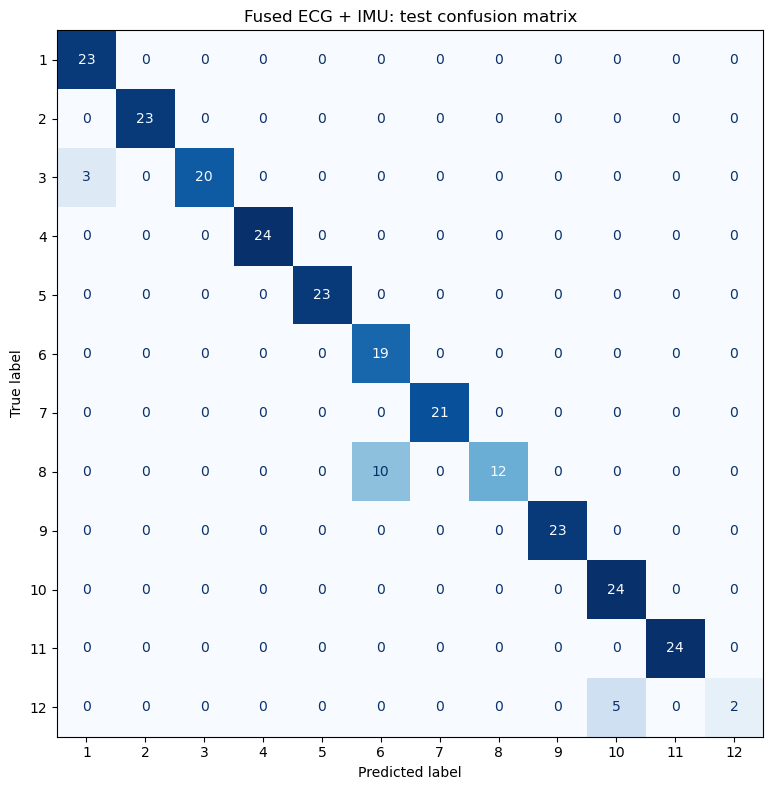

In [21]:
fused_predictions = predictions_by_model["Fused ECG + IMU"]
class_order = np.sort(np.unique(np.concatenate([y_test_eval, fused_predictions])))
cm = confusion_matrix(y_test_eval, fused_predictions, labels=class_order)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_order
)
fig, ax = plt.subplots(figsize=(9, 8))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Fused ECG + IMU: test confusion matrix")
plt.tight_layout()
plt.show()

# Define cross-modal reconstruction model

In [22]:
class CrossModalReconstructionModel(nn.Module):
    def __init__(self, pretrained_model, imu_channels=21, window_size=250):
        super().__init__()
        self.base = pretrained_model

        self.ecg_decoder = nn.Sequential(
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, imu_channels * window_size)
        )
        self.imu_decoder = nn.Sequential(
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 2 * window_size)
        )

        self.imu_channels = imu_channels
        self.window_size = window_size

    def forward(self, ecg, imu):
        h_ecg, _, h_imu, _ = self.base(ecg, imu)

        reconstructed_imu = self.ecg_decoder(h_ecg)
        reconstructed_imu = reconstructed_imu.view(
            -1, self.imu_channels, self.window_size
        )

        reconstructed_ecg = self.imu_decoder(h_imu)
        reconstructed_ecg = reconstructed_ecg.view(-1, 2, self.window_size)

        return h_ecg, h_imu, reconstructed_ecg, reconstructed_imu

# Initialize reconstruction model with an independent copy of the baseline

In [23]:
# Keep the original contrastive baseline unchanged.
reconstruction_base = CrossModalModel().to(DEVICE)
reconstruction_base.load_state_dict(
    torch.load(OUTPUT_DIR / "best_cross_modal_mhealth.pth", map_location=DEVICE)
)
reconstruction_model = CrossModalReconstructionModel(
    reconstruction_base
).to(DEVICE)
print("Independent reconstruction model initialized.")

Independent reconstruction model initialized.


# Define reconstruction training objective

In [24]:
def run_reconstruction_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_losses, ecg_losses, imu_losses = [], [], []

    for ecg, imu in loader:
        ecg, imu = ecg.to(DEVICE), imu.to(DEVICE)

        ecg_aug = augment_signal(ecg)
        imu_aug = augment_signal(imu)

        with torch.set_grad_enabled(training):
            _, _, rec_ecg, rec_imu = model(ecg_aug, imu_aug)

            loss_ecg = F.mse_loss(rec_ecg, ecg)
            loss_imu = F.mse_loss(rec_imu, imu)
            loss_contrastive = contrastive_loss(
                model.base(ecg_aug, imu_aug)[1],
                model.base(ecg_aug, imu_aug)[3]
            )

            loss = loss_contrastive + 0.5 * loss_ecg + 0.5 * loss_imu

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        total_losses.append(loss.item())
        ecg_losses.append(loss_ecg.item())
        imu_losses.append(loss_imu.item())

    return (
        float(np.mean(total_losses)),
        float(np.mean(ecg_losses)),
        float(np.mean(imu_losses))
    )

# Train cross-modal reconstruction model

In [25]:
recon_optimizer = torch.optim.Adam(
    reconstruction_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-5
)
recon_history = {"train": [], "val": []}
best_recon_val = float("inf")
best_recon_state = copy.deepcopy(reconstruction_model.state_dict())

for epoch in range(RECON_EPOCHS):
    train_metrics = run_reconstruction_epoch(
        reconstruction_model, train_loader, recon_optimizer
    )
    val_metrics = run_reconstruction_epoch(
        reconstruction_model, val_loader
    )

    recon_history["train"].append(train_metrics)
    recon_history["val"].append(val_metrics)

    if val_metrics[0] < best_recon_val:
        best_recon_val = val_metrics[0]
        best_recon_state = copy.deepcopy(reconstruction_model.state_dict())
        torch.save(
            best_recon_state,
            OUTPUT_DIR / "best_cross_modal_reconstruction.pth"
        )

    print(
        f"Epoch {epoch + 1:02d}/{RECON_EPOCHS} | "
        f"Train total: {train_metrics[0]:.4f} "
        f"(ECG {train_metrics[1]:.4f}, IMU {train_metrics[2]:.4f}) | "
        f"Val total: {val_metrics[0]:.4f}"
    )
reconstruction_model.load_state_dict(best_recon_state)

Epoch 01/30 | Train total: 3.3959 (ECG 1.0042, IMU 0.9834) | Val total: 5.2522
Epoch 02/30 | Train total: 2.9228 (ECG 0.9973, IMU 0.9563) | Val total: 5.2571
Epoch 03/30 | Train total: 2.6787 (ECG 0.9922, IMU 0.9436) | Val total: 5.3568
Epoch 04/30 | Train total: 2.4943 (ECG 0.9895, IMU 0.9332) | Val total: 5.4649
Epoch 05/30 | Train total: 2.3717 (ECG 0.9858, IMU 0.9255) | Val total: 5.5083
Epoch 06/30 | Train total: 2.2720 (ECG 0.9847, IMU 0.9197) | Val total: 5.4953
Epoch 07/30 | Train total: 2.1759 (ECG 0.9818, IMU 0.9136) | Val total: 5.4411
Epoch 08/30 | Train total: 2.1060 (ECG 0.9739, IMU 0.9072) | Val total: 5.5322
Epoch 09/30 | Train total: 2.0388 (ECG 0.9729, IMU 0.9022) | Val total: 5.5115
Epoch 10/30 | Train total: 1.9835 (ECG 0.9745, IMU 0.8991) | Val total: 5.5352
Epoch 11/30 | Train total: 1.9301 (ECG 0.9662, IMU 0.8931) | Val total: 5.3765
Epoch 12/30 | Train total: 1.8982 (ECG 0.9677, IMU 0.8909) | Val total: 5.4709
Epoch 13/30 | Train total: 1.8629 (ECG 0.9646, IMU 0

<All keys matched successfully>

# Evaluate reconstruction on the held-out test participant

In [26]:
@torch.no_grad()
def evaluate_reconstruction(model, loader):
    model.eval()
    ecg_squared, ecg_absolute = [], []
    imu_squared, imu_absolute = [], []

    for ecg, imu in loader:
        ecg, imu = ecg.to(DEVICE), imu.to(DEVICE)
        _, _, rec_ecg, rec_imu = model(ecg, imu)

        ecg_squared.append(((rec_ecg - ecg) ** 2).cpu().numpy())
        ecg_absolute.append(torch.abs(rec_ecg - ecg).cpu().numpy())
        imu_squared.append(((rec_imu - imu) ** 2).cpu().numpy())
        imu_absolute.append(torch.abs(rec_imu - imu).cpu().numpy())

    ecg_sq = np.concatenate(ecg_squared, axis=0)
    ecg_abs = np.concatenate(ecg_absolute, axis=0)
    imu_sq = np.concatenate(imu_squared, axis=0)
    imu_abs = np.concatenate(imu_absolute, axis=0)

    return {
        "ECG MSE": float(ecg_sq.mean()),
        "ECG MAE": float(ecg_abs.mean()),
        "IMU MSE": float(imu_sq.mean()),
        "IMU MAE": float(imu_abs.mean()),
        "IMU channel MSE": imu_sq.mean(axis=(0, 2)),
        "IMU channel MAE": imu_abs.mean(axis=(0, 2))
    }
reconstruction_metrics = evaluate_reconstruction(
    reconstruction_model, test_loader
)
print("ECG MSE:", reconstruction_metrics["ECG MSE"])
print("ECG MAE:", reconstruction_metrics["ECG MAE"])
print("IMU MSE:", reconstruction_metrics["IMU MSE"])
print("IMU MAE:", reconstruction_metrics["IMU MAE"])
channel_table = pd.DataFrame({
    "Channel": np.arange(1, 22),
    "MSE": reconstruction_metrics["IMU channel MSE"],
    "MAE": reconstruction_metrics["IMU channel MAE"]
})
display(channel_table)
channel_table.to_csv(OUTPUT_DIR / "reconstruction_channel_errors.csv", index=False)

ECG MSE: 0.2675604522228241
ECG MAE: 0.2569126784801483
IMU MSE: 1.0500562191009521
IMU MAE: 0.7280183434486389


,Channel,MSE,MAE
0,1,1.036718,0.723857
1,2,1.597477,0.851132
2,3,1.226390,0.935081
3,4,1.317123,0.689804
4,5,1.315537,0.818460
5,6,1.292787,0.719094
6,7,0.772140,0.766435
7,8,0.994704,0.803925
8,9,1.360050,1.042268
9,10,1.389338,0.699889


# Plot reconstruction errors by inertial channel

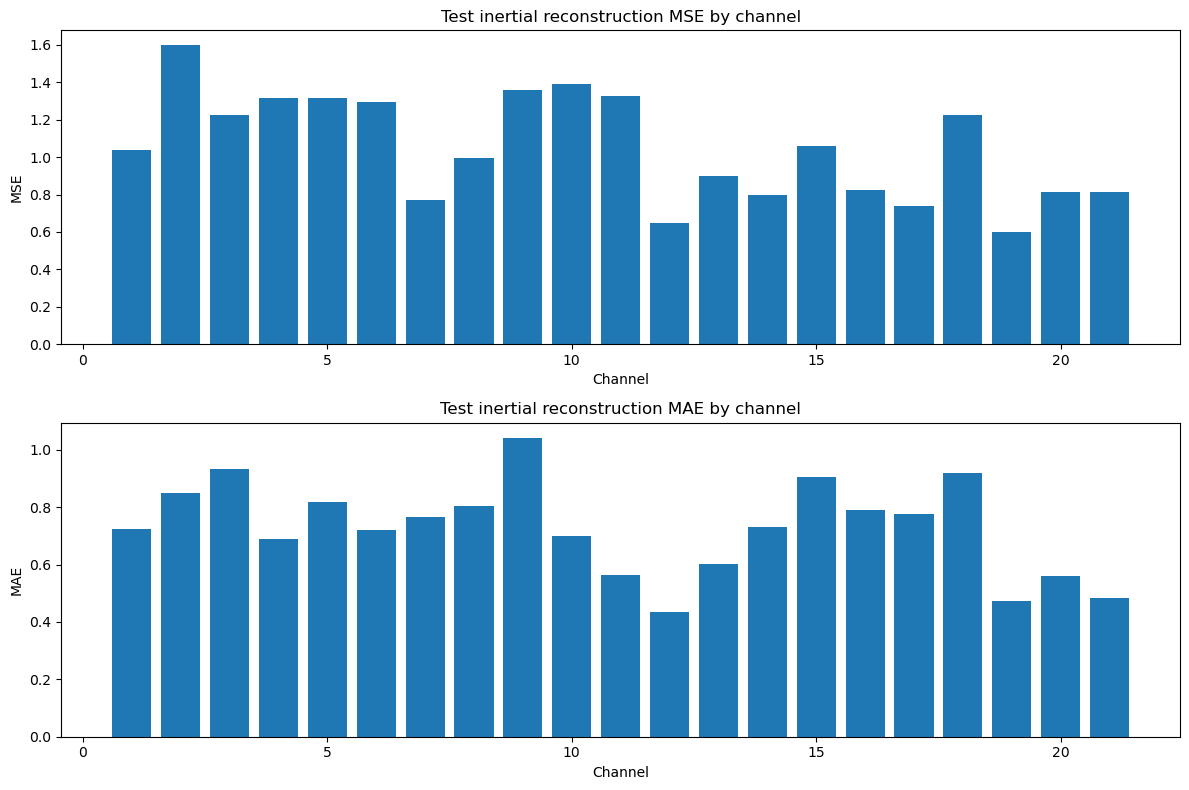

In [27]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
axes[0].bar(channel_table["Channel"], channel_table["MSE"])
axes[0].set_title("Test inertial reconstruction MSE by channel")
axes[0].set_xlabel("Channel")
axes[0].set_ylabel("MSE")
axes[1].bar(channel_table["Channel"], channel_table["MAE"])
axes[1].set_title("Test inertial reconstruction MAE by channel")
axes[1].set_xlabel("Channel")
axes[1].set_ylabel("MAE")
plt.tight_layout()
plt.show()

# Visualize example original and reconstructed signals

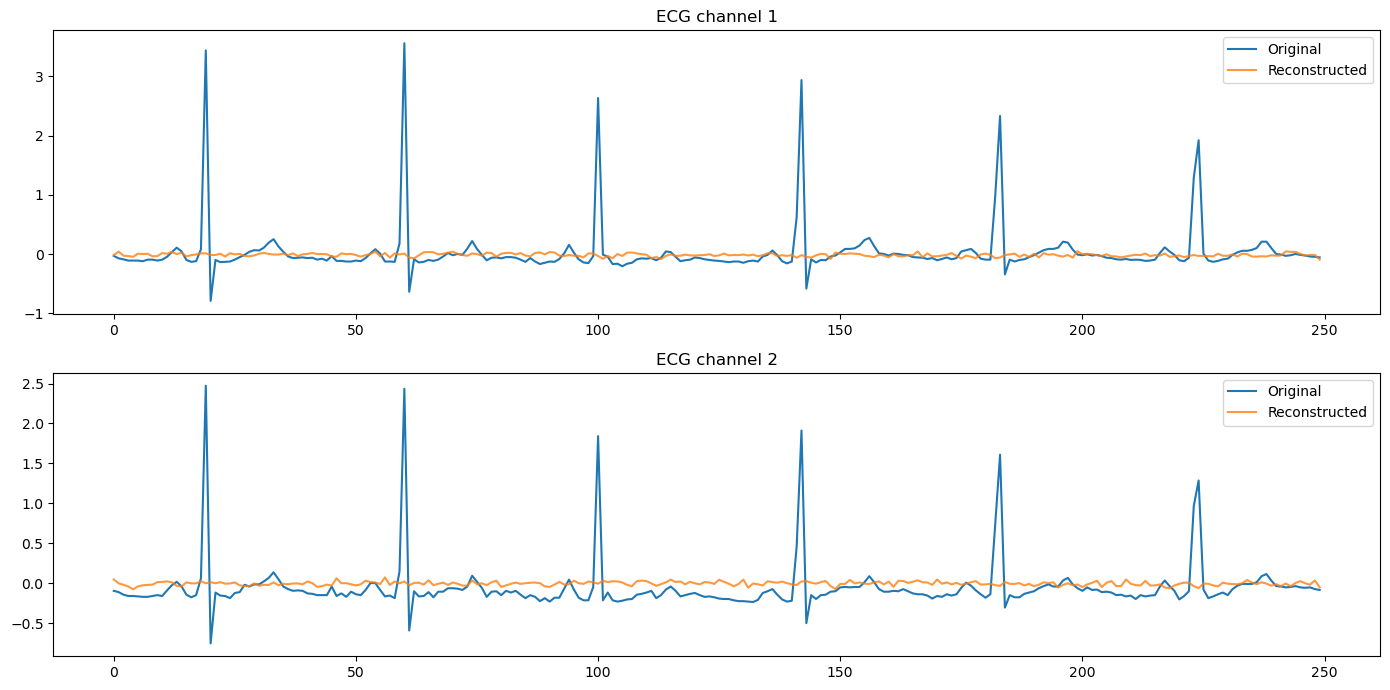

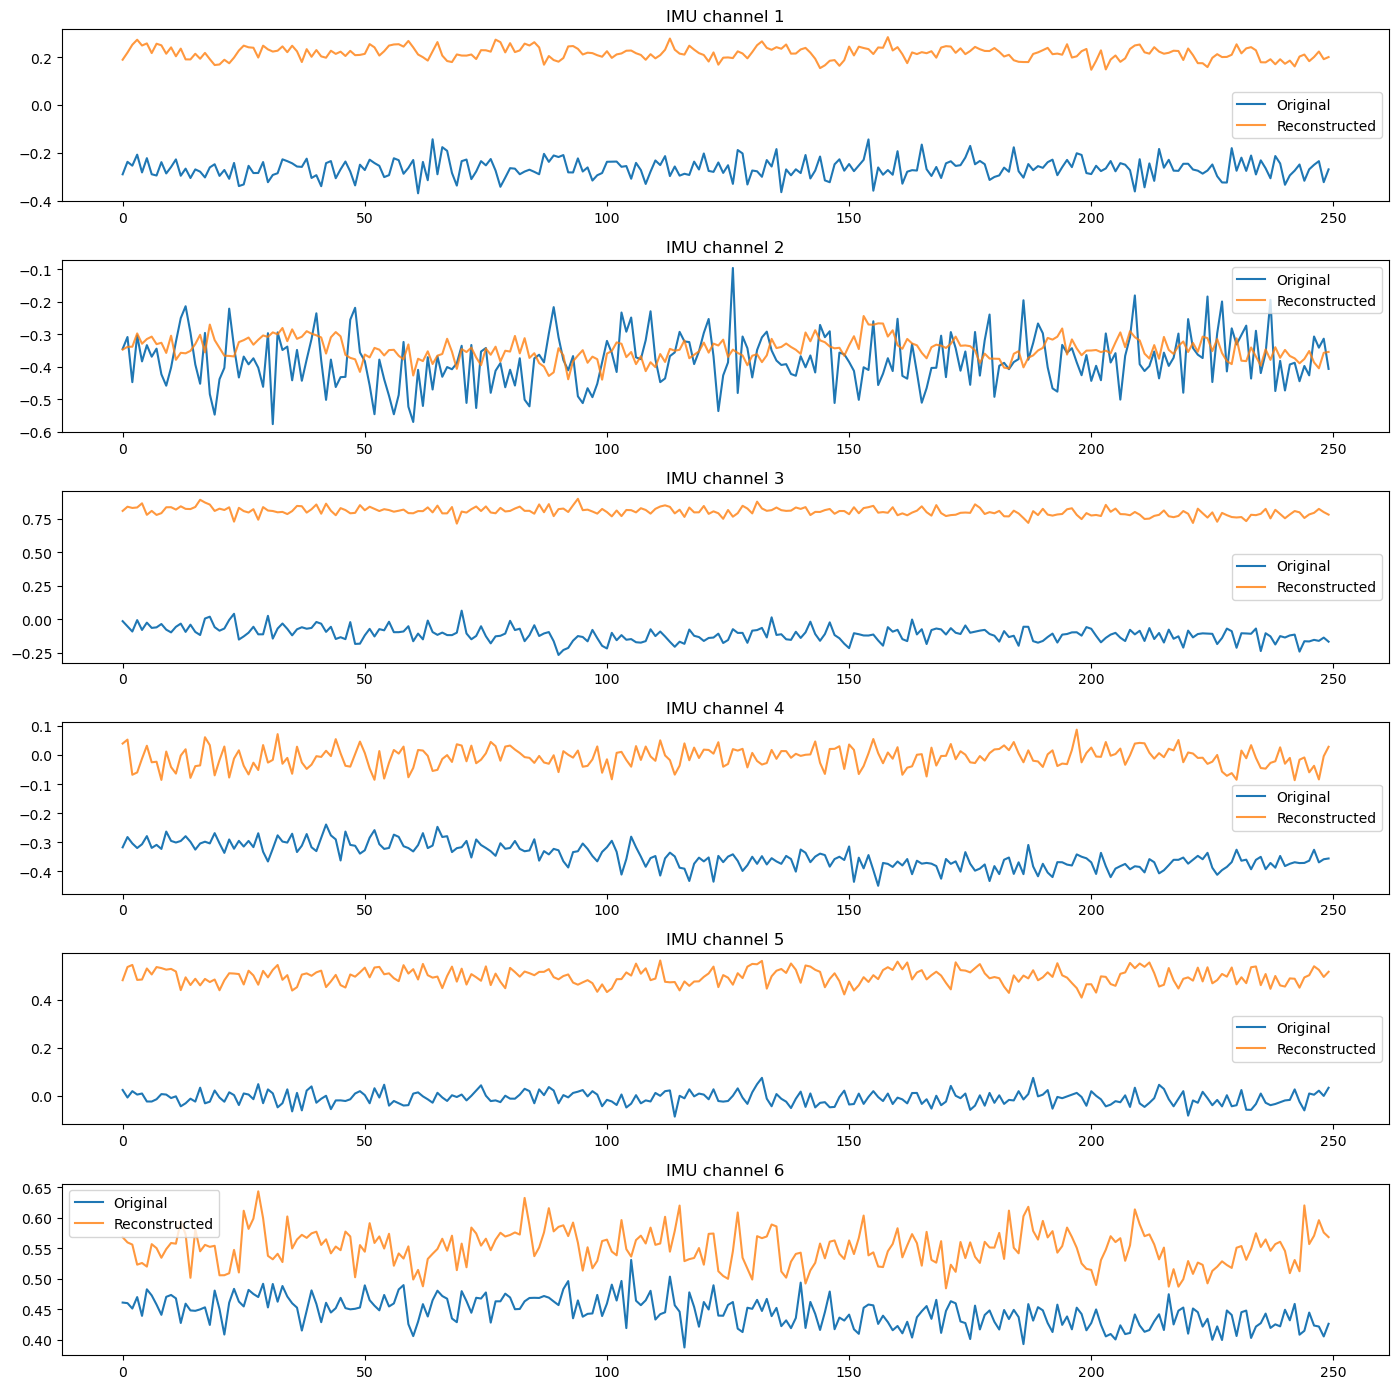

In [28]:
reconstruction_model.eval()
ecg_batch, imu_batch = next(iter(test_loader))
with torch.no_grad():
    _, _, rec_ecg_batch, rec_imu_batch = reconstruction_model(
        ecg_batch.to(DEVICE), imu_batch.to(DEVICE)
    )
original_ecg = ecg_batch[0].numpy()
predicted_ecg = rec_ecg_batch[0].cpu().numpy()
original_imu = imu_batch[0].numpy()
predicted_imu = rec_imu_batch[0].cpu().numpy()
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
for ch in range(2):
    axes[ch].plot(original_ecg[ch], label="Original")
    axes[ch].plot(predicted_ecg[ch], label="Reconstructed", alpha=0.8)
    axes[ch].set_title(f"ECG channel {ch + 1}")
    axes[ch].legend()
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(6, 1, figsize=(14, 14))
for ch, ax in enumerate(axes):
    ax.plot(original_imu[ch], label="Original")
    ax.plot(predicted_imu[ch], label="Reconstructed", alpha=0.8)
    ax.set_title(f"IMU channel {ch + 1}")
    ax.legend()
plt.tight_layout()
plt.show()

# Define modality-ablation model and training helpers

In [39]:
# Modality-ablation model and training helpers

class AblationCrossModalModel(nn.Module):
    def __init__(self, imu_channels):
        super().__init__()
        self.ecg_encoder = SignalEncoder(2)
        self.imu_encoder = SignalEncoder(imu_channels)

    def forward(self, ecg, imu):
        h_ecg, z_ecg = self.ecg_encoder(ecg)
        h_imu, z_imu = self.imu_encoder(imu)
        return h_ecg, z_ecg, h_imu, z_imu
def train_ablation_model(model, train_loader_ab, val_loader_ab,
                         epochs=ABLATION_EPOCHS):
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LEARNING_RATE, weight_decay=1e-5
    )
    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):
        train_loss = run_contrastive_epoch(
            model, train_loader_ab, optimizer
        )
        val_loss = run_contrastive_epoch(model, val_loader_ab)

        if np.isfinite(val_loss) and val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"Train: {train_loss:.4f} | Val: {val_loss:.4f}"
        )

    model.load_state_dict(best_state)
    return model


# Prepare ankle and wrist sensor ablations

In [40]:
# Prepare ankle and wrist sensor ablations
# IMU channel order:
# 0:3   chest accelerometer
# 3:6   ankle accelerometer
# 6:9   ankle gyroscope
# 9:12  ankle magnetometer
# 12:15 wrist accelerometer
# 15:18 wrist gyroscope
# 18:21 wrist magnetometer

NO_ANKLE = list(range(0, 3)) + list(range(12, 21))
NO_WRIST = list(range(0, 12))

def make_ablation_loaders(channel_indices):
    imu_train_ab = X_imu_train[:, :, channel_indices]
    imu_val_ab = X_imu_val[:, :, channel_indices]
    imu_test_ab = X_imu_test[:, :, channel_indices]

    train_ds_ab = PairedSignalDataset(X_ecg_train, imu_train_ab)
    val_ds_ab = PairedSignalDataset(X_ecg_val, imu_val_ab)
    test_ds_ab = PairedSignalDataset(X_ecg_test, imu_test_ab)

    # Training loader: shuffled so contrastive batches vary between epochs.
    # Keep the final partial batch; it contains valid training observations.
    train_dl_ab = DataLoader(
        train_ds_ab,
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=False,
        num_workers=NUM_WORKERS
    )

    # Evaluation loader: never shuffle and never drop samples.
    # This order must match y_train, y_test, and the evaluation masks.
    train_eval_dl_ab = DataLoader(
        train_ds_ab,
        batch_size=BATCH_SIZE,
        shuffle=False,
        drop_last=False,
        num_workers=NUM_WORKERS
    )

    val_dl_ab = DataLoader(
        val_ds_ab,
        batch_size=BATCH_SIZE,
        shuffle=False,
        drop_last=False,
        num_workers=NUM_WORKERS
    )
    test_dl_ab = DataLoader(
        test_ds_ab,
        batch_size=BATCH_SIZE,
        shuffle=False,
        drop_last=False,
        num_workers=NUM_WORKERS
    )

    return {
        "train": train_dl_ab,
        "train_eval": train_eval_dl_ab,
        "validation": val_dl_ab,
        "test": test_dl_ab,
        "train_dataset": train_ds_ab,
        "test_dataset": test_ds_ab
    }
ankle_loaders = make_ablation_loaders(NO_ANKLE)
wrist_loaders = make_ablation_loaders(NO_WRIST)
print("No-ankle channels:", len(NO_ANKLE))
print("No-wrist channels:", len(NO_WRIST))
print("Training windows:", len(X_imu_train))
print("No-ankle ordered extraction windows:",
      len(ankle_loaders["train_eval"].dataset))
print("No-wrist ordered extraction windows:",
      len(wrist_loaders["train_eval"].dataset))
assert len(ankle_loaders["train_eval"].dataset) == len(y_train)
assert len(wrist_loaders["train_eval"].dataset) == len(y_train)

No-ankle channels: 12
No-wrist channels: 12
Training windows: 7846
No-ankle ordered extraction windows: 7846
No-wrist ordered extraction windows: 7846


# Train no-ankle and no-wrist models

In [41]:
# Train independent no-ankle and no-wrist models
torch.manual_seed(SEED)
no_ankle_model = AblationCrossModalModel(len(NO_ANKLE)).to(DEVICE)
no_ankle_model = train_ablation_model(
    no_ankle_model,
    ankle_loaders["train"],
    ankle_loaders["validation"]
)
torch.manual_seed(SEED)
no_wrist_model = AblationCrossModalModel(len(NO_WRIST)).to(DEVICE)
no_wrist_model = train_ablation_model(
    no_wrist_model,
    wrist_loaders["train"],
    wrist_loaders["validation"]
)
torch.save(
    no_ankle_model.state_dict(),
    OUTPUT_DIR / "no_ankle_model.pth"
)
torch.save(
    no_wrist_model.state_dict(),
    OUTPUT_DIR / "no_wrist_model.pth"
)


Epoch 01/30 | Train: 3.3899 | Val: 4.3094
Epoch 02/30 | Train: 2.5917 | Val: 4.3624
Epoch 03/30 | Train: 2.1153 | Val: 4.3907
Epoch 04/30 | Train: 1.8892 | Val: 4.4511
Epoch 05/30 | Train: 1.6972 | Val: 4.6331
Epoch 06/30 | Train: 1.5736 | Val: 4.4560
Epoch 07/30 | Train: 1.4803 | Val: 4.5744
Epoch 08/30 | Train: 1.3837 | Val: 4.6800
Epoch 09/30 | Train: 1.3284 | Val: 4.7731
Epoch 10/30 | Train: 1.2473 | Val: 4.4849
Epoch 11/30 | Train: 1.1899 | Val: 4.7196
Epoch 12/30 | Train: 1.1458 | Val: 4.6523
Epoch 13/30 | Train: 1.0843 | Val: 4.7587
Epoch 14/30 | Train: 1.0594 | Val: 4.7593
Epoch 15/30 | Train: 1.0227 | Val: 4.8045
Epoch 16/30 | Train: 0.9755 | Val: 4.5970
Epoch 17/30 | Train: 0.9344 | Val: 4.7810
Epoch 18/30 | Train: 0.9319 | Val: 4.9658
Epoch 19/30 | Train: 0.8868 | Val: 4.5527
Epoch 20/30 | Train: 0.8718 | Val: 4.8950
Epoch 21/30 | Train: 0.8203 | Val: 4.7097
Epoch 22/30 | Train: 0.8285 | Val: 4.7231
Epoch 23/30 | Train: 0.8192 | Val: 4.7214
Epoch 24/30 | Train: 0.7839 | Val:

# Evaluate ankle and wrist ablations

In [42]:
# Extract correctly ordered representations and evaluate sensor ablations
@torch.no_grad()
def extract_ablation_imu_representations(model, loader):
    model.eval()
    representations = []

    for ecg, imu in loader:
        imu = imu.to(DEVICE)
        h_imu, _ = model.imu_encoder(imu)
        representations.append(h_imu.cpu().numpy())

    if not representations:
        raise RuntimeError("No representations were extracted.")

    return np.concatenate(representations, axis=0)
Z_no_ankle_train = extract_ablation_imu_representations(
    no_ankle_model, ankle_loaders["train_eval"]
)
Z_no_ankle_test = extract_ablation_imu_representations(
    no_ankle_model, ankle_loaders["test"]
)

Z_no_wrist_train = extract_ablation_imu_representations(
    no_wrist_model, wrist_loaders["train_eval"]
)
Z_no_wrist_test = extract_ablation_imu_representations(
    no_wrist_model, wrist_loaders["test"]
)
# Critical alignment checks: one embedding per original window, in original order.
assert len(Z_no_ankle_train) == len(y_train), (
    f"No-ankle train mismatch: {len(Z_no_ankle_train)} embeddings "
    f"versus {len(y_train)} labels"
)
assert len(Z_no_ankle_test) == len(y_test)
assert len(Z_no_wrist_train) == len(y_train), (
    f"No-wrist train mismatch: {len(Z_no_wrist_train)} embeddings "
    f"versus {len(y_train)} labels"
)
assert len(Z_no_wrist_test) == len(y_test)

ablation_rows = []
for name, z_train_ab, z_test_ab in [
    ("No ankle", Z_no_ankle_train, Z_no_ankle_test),
    ("No wrist", Z_no_wrist_train, Z_no_wrist_test)
]:
    result, predictions, classifier = evaluate_linear_probe(
        z_train_ab, z_test_ab, name
    )
    ablation_rows.append(result)

ablation_results = pd.DataFrame(ablation_rows)
display(ablation_results)
ablation_results.to_csv(
    OUTPUT_DIR / "sensor_ablation_results.csv", index=False
)



No ankle
              precision    recall  f1-score   support

           1       1.00      0.30      0.47        23
           2       1.00      0.26      0.41        23
           3       0.00      0.00      0.00        23
           4       0.00      0.00      0.00        24
           5       0.62      0.91      0.74        23
           6       0.47      1.00      0.64        19
           7       1.00      1.00      1.00        21
           8       0.03      0.05      0.04        22
           9       0.57      1.00      0.73        23
          10       1.00      1.00      1.00        24
          11       1.00      1.00      1.00        24
          12       1.00      1.00      1.00         7

    accuracy                           0.60       256
   macro avg       0.64      0.63      0.59       256
weighted avg       0.62      0.60      0.56       256


No wrist
              precision    recall  f1-score   support

           1       0.34      1.00      0.51        23
    

,Representation,Accuracy,Balanced accuracy,Macro F1
0,No ankle,0.597656,0.626976,0.585832
1,No wrist,0.644531,0.654057,0.623227


# ECG-free inertial-only comparison

In [43]:
# ECG-free IMU-only contrastive learning

class IMUOnlyDataset(Dataset):
    def __init__(self, imu_array):
        self.imu = torch.from_numpy(imu_array).permute(0, 2, 1).contiguous()

    def __len__(self):
        return len(self.imu)

    def __getitem__(self, index):
        return self.imu[index]
imu_only_train_dataset = IMUOnlyDataset(X_imu_train)
imu_only_val_dataset = IMUOnlyDataset(X_imu_val)
imu_only_test_dataset = IMUOnlyDataset(X_imu_test)
# Shuffled training batches, retaining every window.
imu_only_train_loader = DataLoader(
    imu_only_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    num_workers=NUM_WORKERS
)
# Ordered loaders are used only for representation extraction/evaluation.
imu_only_train_eval_loader = DataLoader(
    imu_only_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=NUM_WORKERS
)
imu_only_val_loader = DataLoader(
    imu_only_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=NUM_WORKERS
)
imu_only_test_loader = DataLoader(
    imu_only_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=NUM_WORKERS
)
class IMUOnlyContrastiveModel(nn.Module):
    def __init__(self, imu_channels=21):
        super().__init__()
        self.encoder = SignalEncoder(imu_channels)

    def forward(self, view1, view2):
        h1, z1 = self.encoder(view1)
        h2, z2 = self.encoder(view2)
        return h1, z1, h2, z2
def run_imu_only_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    batch_losses = []

    for imu in loader:
        imu = imu.to(DEVICE)
        view1 = augment_signal(imu)
        view2 = augment_signal(imu)

        with torch.set_grad_enabled(training):
            _, z1, _, z2 = model(view1, view2)
            loss = contrastive_loss(z1, z2)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        batch_losses.append(loss.item())

    if not batch_losses:
        raise RuntimeError("The IMU-only loader produced no batches.")

    return float(np.mean(batch_losses))
torch.manual_seed(SEED)
imu_only_model = IMUOnlyContrastiveModel(
    imu_channels=X_imu_train.shape[2]
).to(DEVICE)
imu_only_optimizer = torch.optim.Adam(
    imu_only_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-5
)
best_imu_val_loss = float("inf")
best_imu_state = copy.deepcopy(imu_only_model.state_dict())
for epoch in range(ABLATION_EPOCHS):
    train_loss = run_imu_only_epoch(
        imu_only_model, imu_only_train_loader, imu_only_optimizer
    )
    val_loss = run_imu_only_epoch(
        imu_only_model, imu_only_val_loader
    )

    if np.isfinite(val_loss) and val_loss < best_imu_val_loss:
        best_imu_val_loss = val_loss
        best_imu_state = copy.deepcopy(imu_only_model.state_dict())

    print(
        f"Epoch {epoch + 1:02d}/{ABLATION_EPOCHS} | "
        f"Train: {train_loss:.4f} | Val: {val_loss:.4f}"
    )
imu_only_model.load_state_dict(best_imu_state)
torch.save(
    imu_only_model.state_dict(),
    OUTPUT_DIR / "imu_only_contrastive.pth"
)


Epoch 01/30 | Train: 0.2020 | Val: 1.5333
Epoch 02/30 | Train: 0.0642 | Val: 1.4359
Epoch 03/30 | Train: 0.0578 | Val: 1.3113
Epoch 04/30 | Train: 0.0481 | Val: 1.3412
Epoch 05/30 | Train: 0.0494 | Val: 1.2596
Epoch 06/30 | Train: 0.0448 | Val: 1.2265
Epoch 07/30 | Train: 0.0447 | Val: 1.1985
Epoch 08/30 | Train: 0.0394 | Val: 1.2543
Epoch 09/30 | Train: 0.0387 | Val: 1.1829
Epoch 10/30 | Train: 0.0388 | Val: 1.2160
Epoch 11/30 | Train: 0.0393 | Val: 1.1712
Epoch 12/30 | Train: 0.0396 | Val: 1.1079
Epoch 13/30 | Train: 0.0398 | Val: 1.1297
Epoch 14/30 | Train: 0.0383 | Val: 1.0454
Epoch 15/30 | Train: 0.0372 | Val: 1.1563
Epoch 16/30 | Train: 0.0342 | Val: 1.1296
Epoch 17/30 | Train: 0.0366 | Val: 1.1786
Epoch 18/30 | Train: 0.0361 | Val: 1.1668
Epoch 19/30 | Train: 0.0342 | Val: 1.1788
Epoch 20/30 | Train: 0.0350 | Val: 1.1296
Epoch 21/30 | Train: 0.0351 | Val: 1.1974
Epoch 22/30 | Train: 0.0327 | Val: 1.1121
Epoch 23/30 | Train: 0.0333 | Val: 1.1047
Epoch 24/30 | Train: 0.0323 | Val:

# Extract and evaluate ECG-free representations

In [44]:
@torch.no_grad()
def extract_imu_only_representations(model, loader):
    model.eval()
    representations = []

    for imu in loader:
        imu = imu.to(DEVICE)
        h, _ = model.encoder(imu)
        representations.append(h.cpu().numpy())

    if not representations:
        raise RuntimeError("No ECG-free representations were extracted.")

    return np.concatenate(representations, axis=0)
Z_imu_only_train = extract_imu_only_representations(
    imu_only_model, imu_only_train_eval_loader
)
Z_imu_only_test = extract_imu_only_representations(
    imu_only_model, imu_only_test_loader
)
assert len(Z_imu_only_train) == len(y_train), (
    f"ECG-free train mismatch: {len(Z_imu_only_train)} embeddings "
    f"versus {len(y_train)} labels"
)
assert len(Z_imu_only_test) == len(y_test), (
    f"ECG-free test mismatch: {len(Z_imu_only_test)} embeddings "
    f"versus {len(y_test)} labels"
)
no_ecg_result, no_ecg_predictions, no_ecg_classifier = evaluate_linear_probe(
    Z_imu_only_train,
    Z_imu_only_test,
    "No ECG (IMU-only contrastive)"
)
display(pd.DataFrame([no_ecg_result]))


No ECG (IMU-only contrastive)
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       1.00      1.00      1.00        23
           3       0.00      0.00      0.00        23
           4       1.00      0.92      0.96        24
           5       1.00      0.96      0.98        23
           6       0.59      1.00      0.75        19
           7       1.00      1.00      1.00        21
           8       0.75      0.41      0.53        22
           9       1.00      1.00      1.00        23
          10       1.00      1.00      1.00        24
          11       0.51      1.00      0.68        24
          12       1.00      1.00      1.00         7

    accuracy                           0.85       256
   macro avg       0.82      0.86      0.82       256
weighted avg       0.81      0.85      0.81       256



,Representation,Accuracy,Balanced accuracy,Macro F1
0,No ECG (IMU-only contrastive),0.847656,0.856857,0.823739


# Combine baseline and sensor ablation results

,Representation,Accuracy,Balanced accuracy,Macro F1
0,ECG only,0.316406,0.295247,0.240250
1,IMU only,0.925781,0.932449,0.909927
2,Fused ECG + IMU,0.929688,0.891728,0.893055
3,No ankle,0.597656,0.626976,0.585832
4,No wrist,0.644531,0.654057,0.623227
5,No ECG (IMU-only contrastive),0.847656,0.856857,0.823739


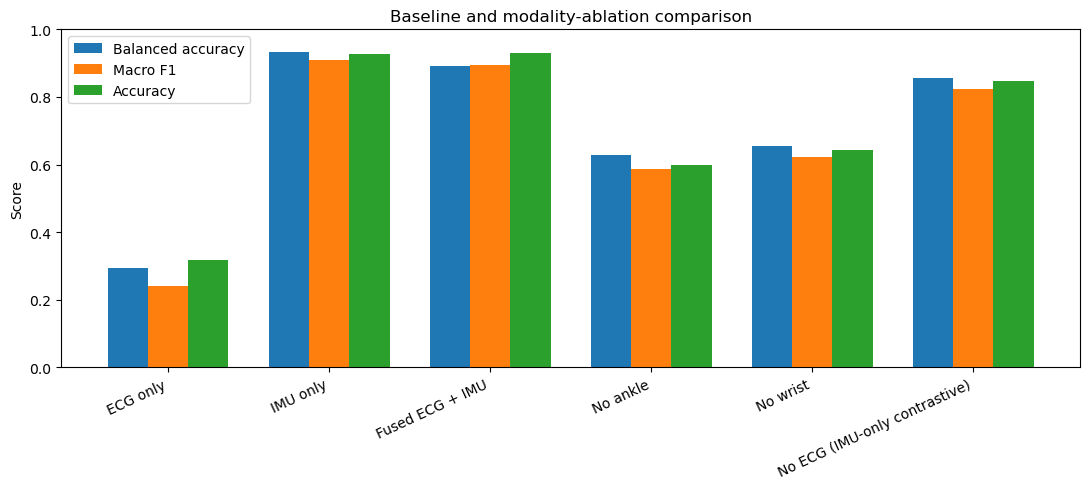

In [45]:
all_comparisons = pd.concat(
    [
        baseline_results,
        ablation_results,
        pd.DataFrame([no_ecg_result])
    ],
    ignore_index=True
)

display(all_comparisons)
all_comparisons.to_csv(
    OUTPUT_DIR / "all_modality_comparisons.csv", index=False
)

plt.figure(figsize=(11, 5))
x = np.arange(len(all_comparisons))
plt.bar(
    x - 0.25, all_comparisons["Balanced accuracy"],
    width=0.25, label="Balanced accuracy"
)
plt.bar(
    x, all_comparisons["Macro F1"],
    width=0.25, label="Macro F1"
)
plt.bar(
    x + 0.25, all_comparisons["Accuracy"],
    width=0.25, label="Accuracy"
)
plt.xticks(
    x, all_comparisons["Representation"],
    rotation=25, ha="right"
)
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("Baseline and modality-ablation comparison")
plt.legend()
plt.tight_layout()
plt.show()

# Prepare test embeddings for t-SNE

In [46]:
tsne_mask = (y_test != 0) & (purity_test >= 0.80)
# Confirm the baseline embeddings preserve the original test-window order.
assert len(Z_ecg_test) == len(y_test)
assert len(Z_imu_test) == len(y_test)
ecg_tsne = Z_ecg_test[tsne_mask]
imu_tsne = Z_imu_test[tsne_mask]
labels_tsne = y_test[tsne_mask]
paired_embeddings = np.concatenate(
    [ecg_tsne, imu_tsne], axis=0
)
paired_labels = np.concatenate(
    [labels_tsne, labels_tsne], axis=0
)
modality_labels = np.array(
    ["ECG"] * len(ecg_tsne) + ["IMU"] * len(imu_tsne)
)
print("Eligible test windows:", int(tsne_mask.sum()))
print("Paired embeddings for t-SNE:", paired_embeddings.shape)

Eligible test windows: 256
Paired embeddings for t-SNE: (512, 128)


# Compute and plot t-SNE

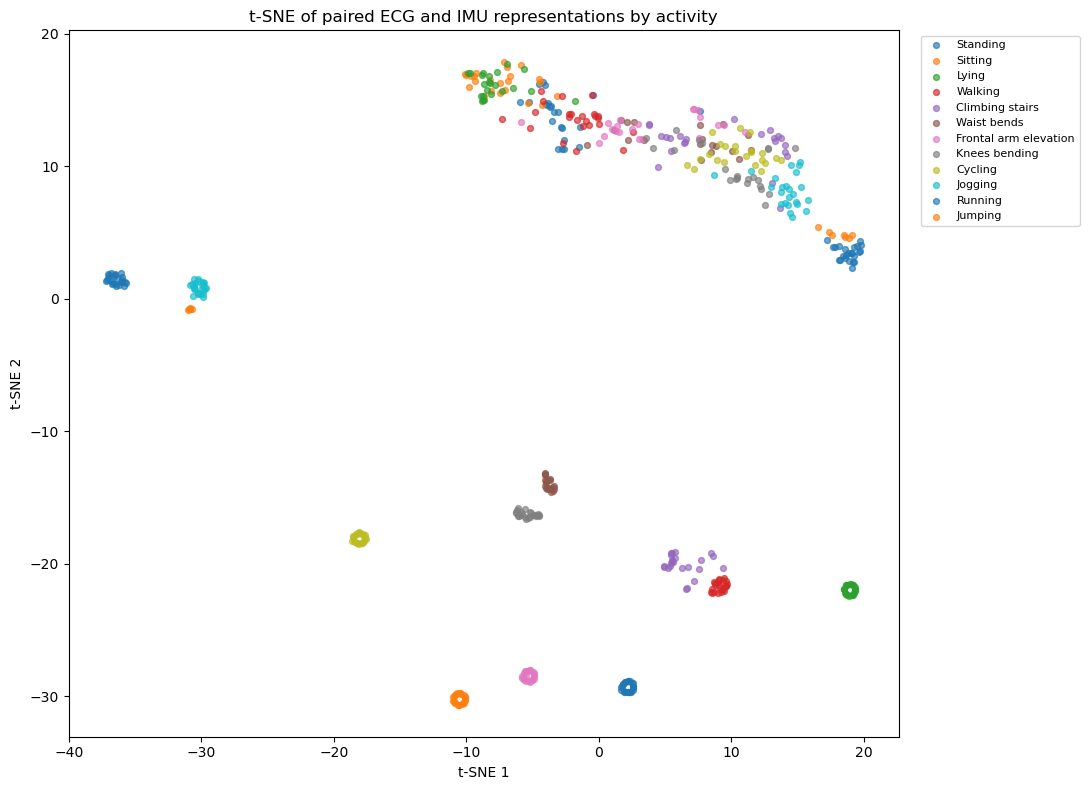

In [47]:
if len(paired_embeddings) >= 4:
    perplexity_value = min(
        30, max(2, (len(paired_embeddings) - 1) // 3)
    )

    tsne = TSNE(
        n_components=2,
        perplexity=perplexity_value,
        learning_rate="auto",
        init="pca",
        random_state=SEED
    )
    embedding_2d = tsne.fit_transform(paired_embeddings)

    plt.figure(figsize=(11, 8))
    for activity in np.unique(paired_labels):
        activity_mask = paired_labels == activity
        plt.scatter(
            embedding_2d[activity_mask, 0],
            embedding_2d[activity_mask, 1],
            label=activity_names.get(int(activity), str(activity)),
            alpha=0.65,
            s=18
        )

    plt.title("t-SNE of paired ECG and IMU representations by activity")
    plt.xlabel("t-SNE 1")
    plt.ylabel("t-SNE 2")
    plt.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=8
    )
    plt.tight_layout()
    plt.show()
else:
    print("Not enough eligible samples for t-SNE.")


# Visualize cross-modal paired embeddings

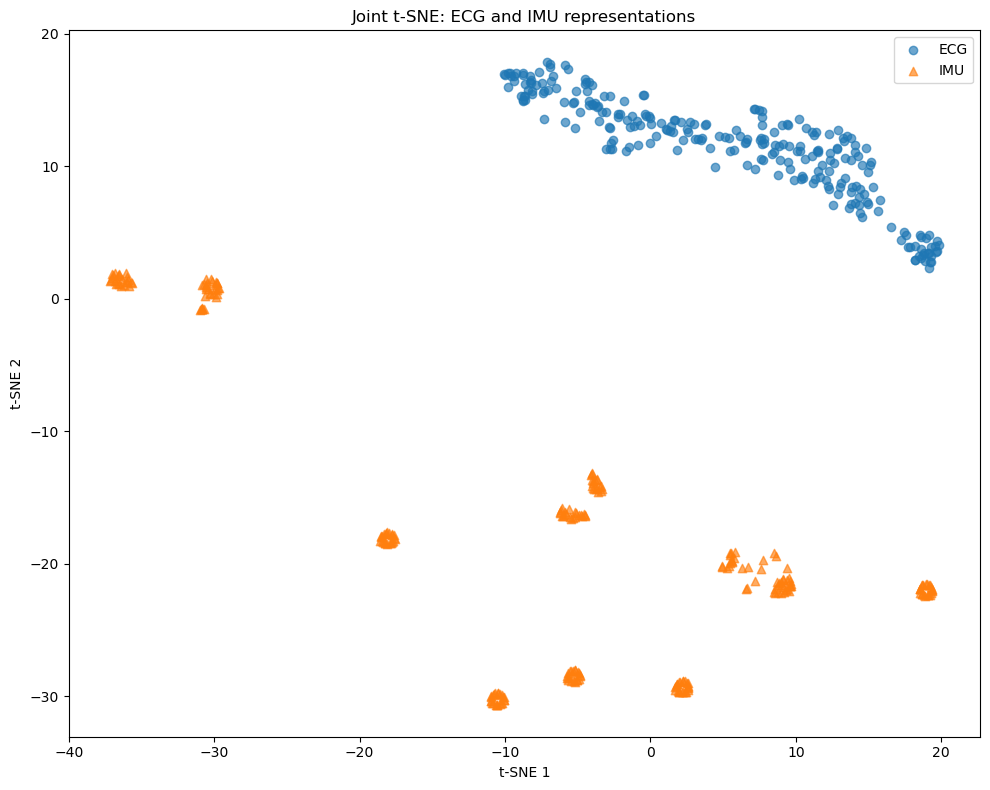

In [48]:
# Visualize ECG and IMU modalities in the joint t-SNE space
if len(paired_embeddings) >= 4:
    n_pairs = len(ecg_tsne)

    plt.figure(figsize=(10, 8))
    plt.scatter(
        embedding_2d[:n_pairs, 0],
        embedding_2d[:n_pairs, 1],
        marker="o",
        alpha=0.65,
        label="ECG"
    )
    plt.scatter(
        embedding_2d[n_pairs:, 0],
        embedding_2d[n_pairs:, 1],
        marker="^",
        alpha=0.65,
        label="IMU"
    )

    plt.title("Joint t-SNE: ECG and IMU representations")
    plt.xlabel("t-SNE 1")
    plt.ylabel("t-SNE 2")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [49]:
# Cross-modal retrieval evaluation
def retrieval_metrics(z_ecg, z_imu):
    if z_ecg.ndim != 2 or z_imu.ndim != 2:
        raise ValueError("Retrieval inputs must be two-dimensional arrays.")
    if len(z_ecg) != len(z_imu):
        raise ValueError("ECG and IMU retrieval arrays must have equal lengths.")
    if len(z_ecg) == 0:
        raise ValueError("No test pairs are available for retrieval.")

    ecg_norm = z_ecg / (
        np.linalg.norm(z_ecg, axis=1, keepdims=True) + 1e-8
    )
    imu_norm = z_imu / (
        np.linalg.norm(z_imu, axis=1, keepdims=True) + 1e-8
    )

    similarity = ecg_norm @ imu_norm.T
    n_pairs = similarity.shape[0]

    ranked_indices = np.argsort(-similarity, axis=1)
    correct_indices = np.arange(n_pairs)

    top1 = np.mean(ranked_indices[:, 0] == correct_indices)
    top_k = min(5, n_pairs)
    top5 = np.mean([
        correct_indices[i] in ranked_indices[i, :top_k]
        for i in range(n_pairs)
    ])
    positive_similarity = np.mean(
        similarity[correct_indices, correct_indices]
    )

    metrics = {
        "Number of pairs": n_pairs,
        "Mean positive cosine similarity": positive_similarity,
        "Top-1 retrieval": top1,
        "Top-5 retrieval": top5,
        "Random top-1 reference": 1.0 / n_pairs
    }

    return metrics, similarity

# Retrieval uses aligned held-out test windows from the baseline model.
retrieval_result, retrieval_similarity = retrieval_metrics(
    Z_ecg_test, Z_imu_test
)
display(pd.DataFrame([retrieval_result]))


,Number of pairs,Mean positive cosine similarity,Top-1 retrieval,Top-5 retrieval,Random top-1 reference
0,785,0.088885,0.002548,0.008917,0.001274


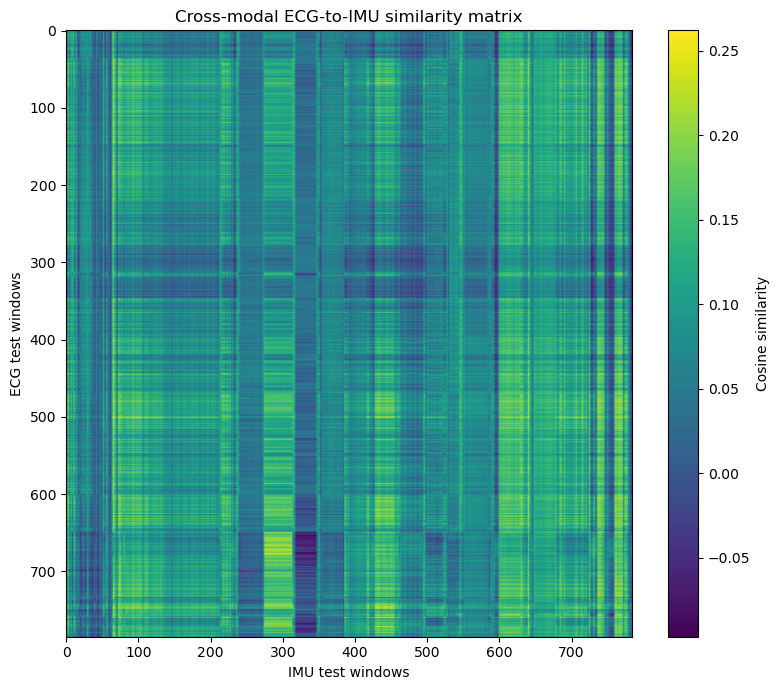

In [50]:
# Plot cross-modal ECG-to-IMU similarity matrix
plt.figure(figsize=(8, 7))
plt.imshow(retrieval_similarity, aspect="auto", cmap="viridis")
plt.colorbar(label="Cosine similarity")
plt.xlabel("IMU test windows")
plt.ylabel("ECG test windows")
plt.title("Cross-modal ECG-to-IMU similarity matrix")
plt.tight_layout()
plt.show()

In [51]:
# Save representations, labels, metrics, and project summary
np.savez_compressed(
    OUTPUT_DIR / "mhealth_embeddings_and_labels.npz",
    Z_ecg_train=Z_ecg_train,
    Z_imu_train=Z_imu_train,
    Z_ecg_test=Z_ecg_test,
    Z_imu_test=Z_imu_test,
    Z_no_ankle_train=Z_no_ankle_train,
    Z_no_ankle_test=Z_no_ankle_test,
    Z_no_wrist_train=Z_no_wrist_train,
    Z_no_wrist_test=Z_no_wrist_test,
    Z_imu_only_train=Z_imu_only_train,
    Z_imu_only_test=Z_imu_only_test,
    y_train=y_train,
    y_test=y_test,
    purity_train=purity_train,
    purity_test=purity_test
)

summary = {
    "Total windows": int(len(y)),
    "Training windows": int(len(y_train)),
    "Validation windows": int(len(y_val)),
    "Test windows": int(len(y_test)),
    "ECG test reconstruction MSE": reconstruction_metrics["ECG MSE"],
    "ECG test reconstruction MAE": reconstruction_metrics["ECG MAE"],
    "IMU test reconstruction MSE": reconstruction_metrics["IMU MSE"],
    "IMU test reconstruction MAE": reconstruction_metrics["IMU MAE"],
    "Cross-modal retrieval top-1": retrieval_result["Top-1 retrieval"],
    "Cross-modal retrieval top-5": retrieval_result["Top-5 retrieval"]
}
summary_df = pd.DataFrame([summary])
display(summary_df)
summary_df.to_csv(OUTPUT_DIR / "project_summary.csv", index=False)
print("All project outputs saved to:", OUTPUT_DIR.resolve())

,Total windows,Training windows,Validation windows,Test windows,ECG test reconstruction MSE,ECG test reconstruction MAE,IMU test reconstruction MSE,IMU test reconstruction MAE,Cross-modal retrieval top-1,Cross-modal retrieval top-5
0,9711,7846,1080,785,0.26756,0.256913,1.050056,0.728018,0.002548,0.008917


All project outputs saved to: C:\Users\user\mhealth_outputs
